# Behavior alignment with selectable dF/F correction

This notebook aligns ScanImage frame times to pyControl behavior exactly once, then loads one dF/F method saved by `compare_F_F0_dff.ipynb`. Change only `DFF_METHOD` to repeat the downstream analysis with another correction.

In [1]:
from pathlib import Path
import importlib.util
import json
import pickle
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if ROOT.name == 'scripts':
    ROOT = ROOT.parent

## Configuration

In [2]:
# H5 and behavior TSV must come from the same acquisition.
H5_PATH = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/file_00389.h5')
BEHAVIOR_TSV = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/behav/MY_71_R-2026-06-24-191859.tsv')
BEHAVIOR_PROJECT = Path('/Users/megyoung/magnitude-bandit-analysis')

# This is RESULTS_DIR from compare_F_F0_dff.ipynb.
DFF_DIR = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/plane0/dff_comparison')

# Select one key printed by the next cell.
DFF_METHOD = 'paired_red_ols'
USE_ARTIFACT_REMOVED = True  # False loads the method before frame masking

TRACE_VARIANT = 'artifact_removed' if USE_ARTIFACT_REMOVED else 'unmasked'
OUTPUT_DIR = DFF_DIR / 'behavior_alignment' / DFF_METHOD / TRACE_VARIANT
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ALIGN_SCRIPT = ROOT / 'scripts' / 'align_scanimage_pycontrol.py'
ALIGN_PYTHON = Path(sys.executable)
if importlib.util.find_spec('h5py') is None:
    ALIGN_PYTHON = Path('/Users/megyoung/anaconda3/bin/python')

for path in (H5_PATH, BEHAVIOR_TSV, BEHAVIOR_PROJECT, ALIGN_SCRIPT, DFF_DIR / 'dff_methods.json'):
    if not path.exists():
        raise FileNotFoundError(f'Update the configuration; not found: {path}')

## Inspect and select a saved method

In [3]:
with (DFF_DIR / 'dff_methods.json').open() as handle:
    manifest = json.load(handle)

print('Available methods:')
for slug, info in manifest['methods'].items():
    print(f"  {slug:32s} — {info['display_name']}")
if DFF_METHOD not in manifest['methods']:
    raise KeyError(f'Unknown DFF_METHOD={DFF_METHOD!r}')

method_info = manifest['methods'][DFF_METHOD]
file_key = 'artifact_removed_dff_file' if USE_ARTIFACT_REMOVED else 'dff_file'
if file_key not in method_info:
    raise KeyError(
        f'{file_key!r} is absent from the manifest. Rerun the save cell in compare_F_F0_dff.ipynb.')
DFF_PATH = DFF_DIR / method_info[file_key]
if not DFF_PATH.exists():
    raise FileNotFoundError(DFF_PATH)
print('Selected:', method_info['display_name'])
print('Variant:', TRACE_VARIANT)
print('Trace file:', DFF_PATH)

Available methods:
  standard_green                   — standard green
  legacy_g_over_r_ratio            — legacy G/R ratio
  global_red_huber                 — global-red regression
  paired_red_huber                 — paired-red regression
  paired_red_ols                   — paired-red OLS
  paired_red_ols_unscaled          — paired-red OLS unscaled
  red_transition_weighted_ridge    — red-transition weighted Ridge
Selected: paired-red OLS
Variant: artifact_removed
Trace file: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/plane0/dff_comparison/dff_paired_red_ols_artifact_nan.npy


## Align ScanImage and behavioral clocks

ScanImage frames: 14000
Rsync pulses: pyControl=365, ScanImage=365, matched=365
Aligned frames within rsync coverage: 13949/14000
Saved: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/plane0/dff_comparison/behavior_alignment/paired_red_ols/artifact_removed/aligned_session.pkl



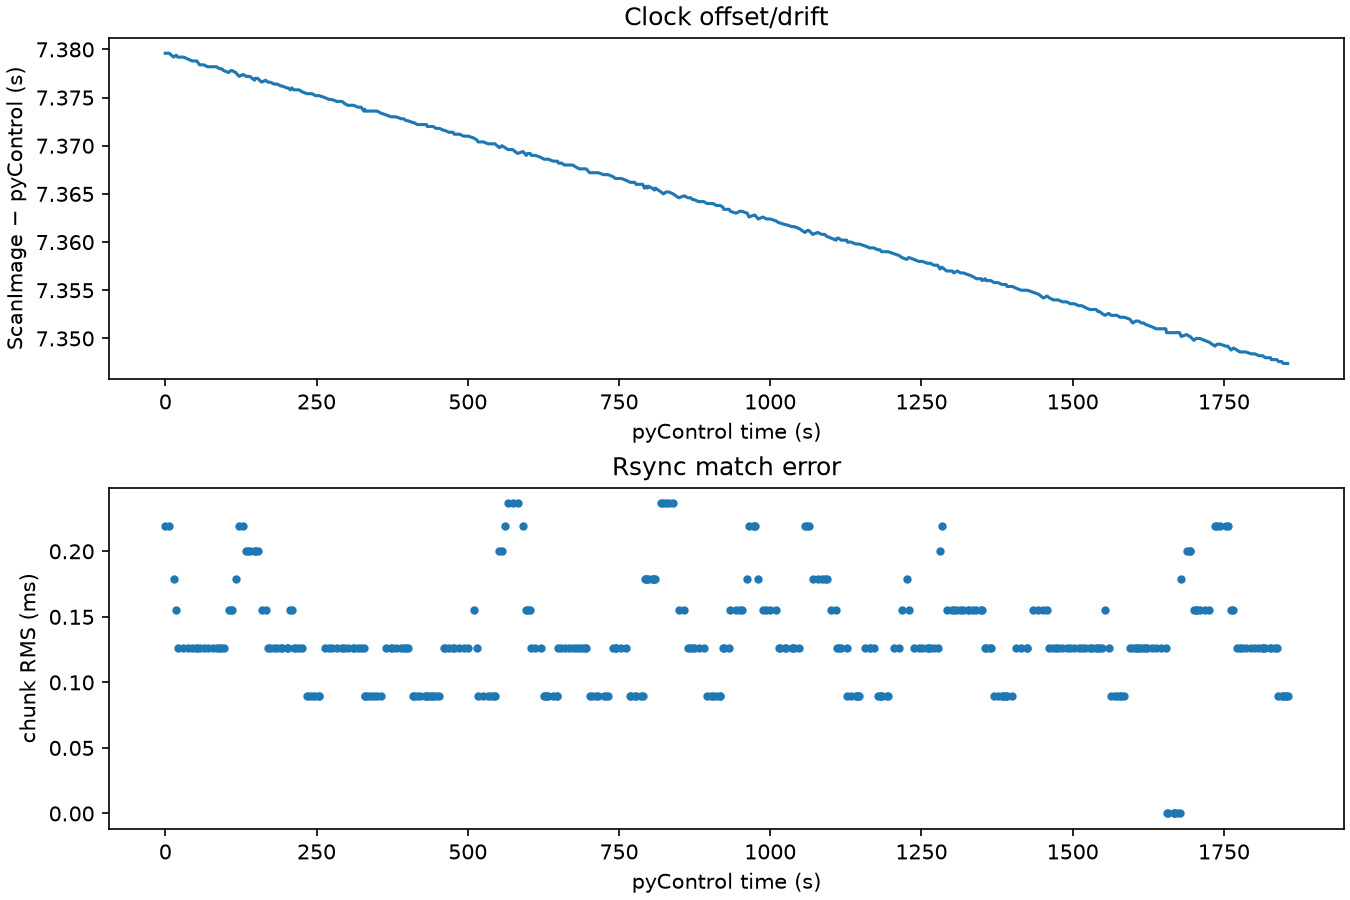

In [4]:
ALIGNED_SESSION = OUTPUT_DIR / 'aligned_session.pkl'
QC_PLOT = OUTPUT_DIR / 'rsync_qc.png'
command = [
    str(ALIGN_PYTHON), str(ALIGN_SCRIPT), '--h5', str(H5_PATH),
    '--behavior-tsv', str(BEHAVIOR_TSV), '--output', str(ALIGNED_SESSION),
    '--behavior-project', str(BEHAVIOR_PROJECT), '--plot', str(QC_PLOT),
]
result = subprocess.run(command, check=False, text=True, capture_output=True)
if result.stdout:
    print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(f'Alignment failed with exit code {result.returncode}')
with ALIGNED_SESSION.open('rb') as handle:
    session = pickle.load(handle)
display(Image(filename=str(QC_PLOT)))

In [5]:
rsync = session['rsync']
print(f"Matched pulses: {len(rsync['matched_pycontrol_indices'])}")
print(f"Median chunk RMS: {np.median(rsync['chunk_rms_s']) * 1000:.3f} ms")
print(f"Maximum chunk RMS: {np.max(rsync['chunk_rms_s']) * 1000:.3f} ms")
print(f"Frames inside rsync coverage: {session['frame_valid'].sum()} / {len(session['frame_valid'])}")

Matched pulses: 365
Median chunk RMS: 0.126 ms
Maximum chunk RMS: 0.237 ms
Frames inside rsync coverage: 13949 / 14000


## Load the selected traces and reconcile valid frames

In [6]:
dff = np.load(DFF_PATH, mmap_mode='r')
all_frame_times = np.asarray(session['frame_times_pycontrol_s'], dtype=float)
all_clock_valid = np.asarray(session['frame_valid'], dtype=bool) & np.isfinite(all_frame_times)

valid_frames_path = manifest.get('valid_frames_path')
if valid_frames_path is not None:
    with np.load(valid_frames_path) as valid_file:
        selector = np.asarray(valid_file['valid_frames'])
    if selector.dtype == bool:
        if selector.size == all_frame_times.size + 1:
            selector_for_clock = selector[:-1]
        elif selector.size == all_frame_times.size:
            selector_for_clock = selector
        else:
            raise ValueError('Boolean valid_frames length does not match the H5 frame clock')
    else:
        selector_for_clock = selector.astype(int)
        selector_for_clock = selector_for_clock[selector_for_clock < all_frame_times.size]
    frame_times = all_frame_times[selector_for_clock]
    clock_valid = all_clock_valid[selector_for_clock]
else:
    frame_times = all_frame_times
    clock_valid = all_clock_valid

if dff.shape[1] == len(frame_times) + 1:
    print('Dropping one final unclocked trace frame.')
    dff = dff[:, :len(frame_times)]
elif dff.shape[1] != len(frame_times):
    raise ValueError(
        f'{DFF_METHOD} has {dff.shape[1]} frames but alignment supplies {len(frame_times)}. '
        'Check that both notebooks used the same acquisition and valid_frames.npz.')

dff_array = np.asarray(dff, dtype=np.float32)
valid_roi_indices = np.flatnonzero(np.any(np.isfinite(dff_array), axis=1))
frame_rate = 1 / np.nanmedian(np.diff(frame_times[np.isfinite(frame_times)]))
print('Method:', method_info['display_name'])
print('ROIs × aligned frames:', dff_array.shape)
print('Valid ROIs:', len(valid_roi_indices))
print(f'Frame rate: {frame_rate:.4f} Hz')

Dropping one final unclocked trace frame.
Method: paired-red OLS
ROIs × aligned frames: (254, 14000)
Valid ROIs: 254
Frame rate: 7.5186 Hz


## Reward events and analysis settings

In [7]:
reward_pulses = np.asarray(session['reward_pulses'], dtype=float)
rewarded_trials = np.flatnonzero(reward_pulses > 0)
reward_onsets_s = np.asarray(session['events']['choice']['time_s'], dtype=float)
if len(reward_onsets_s) != len(rewarded_trials):
    raise ValueError('Rewarded-trial count does not match choice-state event count.')
covered = (reward_onsets_s >= np.nanmin(frame_times)) & (reward_onsets_s <= np.nanmax(frame_times))
reward_onsets_s = reward_onsets_s[covered]
rewarded_trials = rewarded_trials[covered]
reward_magnitudes = reward_pulses[rewarded_trials]
print('Rewarded trials in coverage:', len(reward_onsets_s))

WINDOW_S = (-5.0, 10.0)
BASELINE_S = (-2.0, -0.5)
BASELINE_CORRECT = True
TRACE_DISPLAY_PERCENTILES = (1.0, 99.0)
EXCLUDE_POPULATION_ARTIFACTS = True
CELL_DERIVATIVE_Z = 3.0
MIN_FRACTION_CELLS = 0.25
ARTIFACT_PADDING_FRAMES = 1

Rewarded trials in coverage: 32


## Detect residual population-wide artifacts

In [8]:
if EXCLUDE_POPULATION_ARTIFACTS:
    derivative = np.diff(dff_array.astype(float), axis=1, prepend=dff_array[:, :1])
    center = np.nanmedian(derivative, axis=1, keepdims=True)
    mad = np.nanmedian(np.abs(derivative - center), axis=1, keepdims=True)
    scale = 1.4826 * mad
    scale[scale < 1e-12] = np.nan
    derivative_z = (derivative - center) / scale
    cells_spiking = np.abs(derivative_z) >= CELL_DERIVATIVE_Z
    fraction_spiking = np.nanmean(cells_spiking[valid_roi_indices], axis=0)
    artifact_frames = fraction_spiking >= MIN_FRACTION_CELLS
    if ARTIFACT_PADDING_FRAMES:
        kernel = np.ones(2 * ARTIFACT_PADDING_FRAMES + 1, dtype=int)
        artifact_frames = np.convolve(artifact_frames.astype(int), kernel, mode='same') > 0
else:
    artifact_frames = np.zeros(dff_array.shape[1], dtype=bool)
trace_valid = clock_valid[None, :] & (~artifact_frames)[None, :] & np.isfinite(dff_array)
print('Residual population-artifact frames excluded:', artifact_frames.sum())
print(f'Mean retained samples: {100 * trace_valid.mean():.2f}%')

Residual population-artifact frames excluded: 0
Mean retained samples: 97.12%


## Build the peri-reward array

In [9]:
dt = np.nanmedian(np.diff(frame_times[np.isfinite(frame_times)]))
relative_time = np.arange(WINDOW_S[0], WINDOW_S[1] + dt / 2, dt)
peri_reward = np.full(
    (len(reward_onsets_s), dff_array.shape[0], len(relative_time)),
    np.nan, dtype=np.float32)
for trial_i, onset in enumerate(reward_onsets_s):
    sample_times = onset + relative_time
    for roi in valid_roi_indices:
        keep = trace_valid[roi]
        if np.count_nonzero(keep) < 2:
            continue
        values = np.interp(
            sample_times, frame_times[keep], dff_array[roi, keep],
            left=np.nan, right=np.nan)
        peri_reward[trial_i, roi] = values
if BASELINE_CORRECT:
    baseline_mask = (relative_time >= BASELINE_S[0]) & (relative_time < BASELINE_S[1])
    peri_reward -= np.nanmean(peri_reward[:, :, baseline_mask], axis=2, keepdims=True)
print('Peri-reward shape (trials × ROIs × time):', peri_reward.shape)
np.savez_compressed(
    OUTPUT_DIR / 'peri_reward.npz', peri_reward=peri_reward,
    relative_time=relative_time, reward_magnitudes=reward_magnitudes,
    valid_roi_indices=valid_roi_indices, method=DFF_METHOD)

Peri-reward shape (trials × ROIs × time): (32, 254, 114)


## Per-cell reward responses

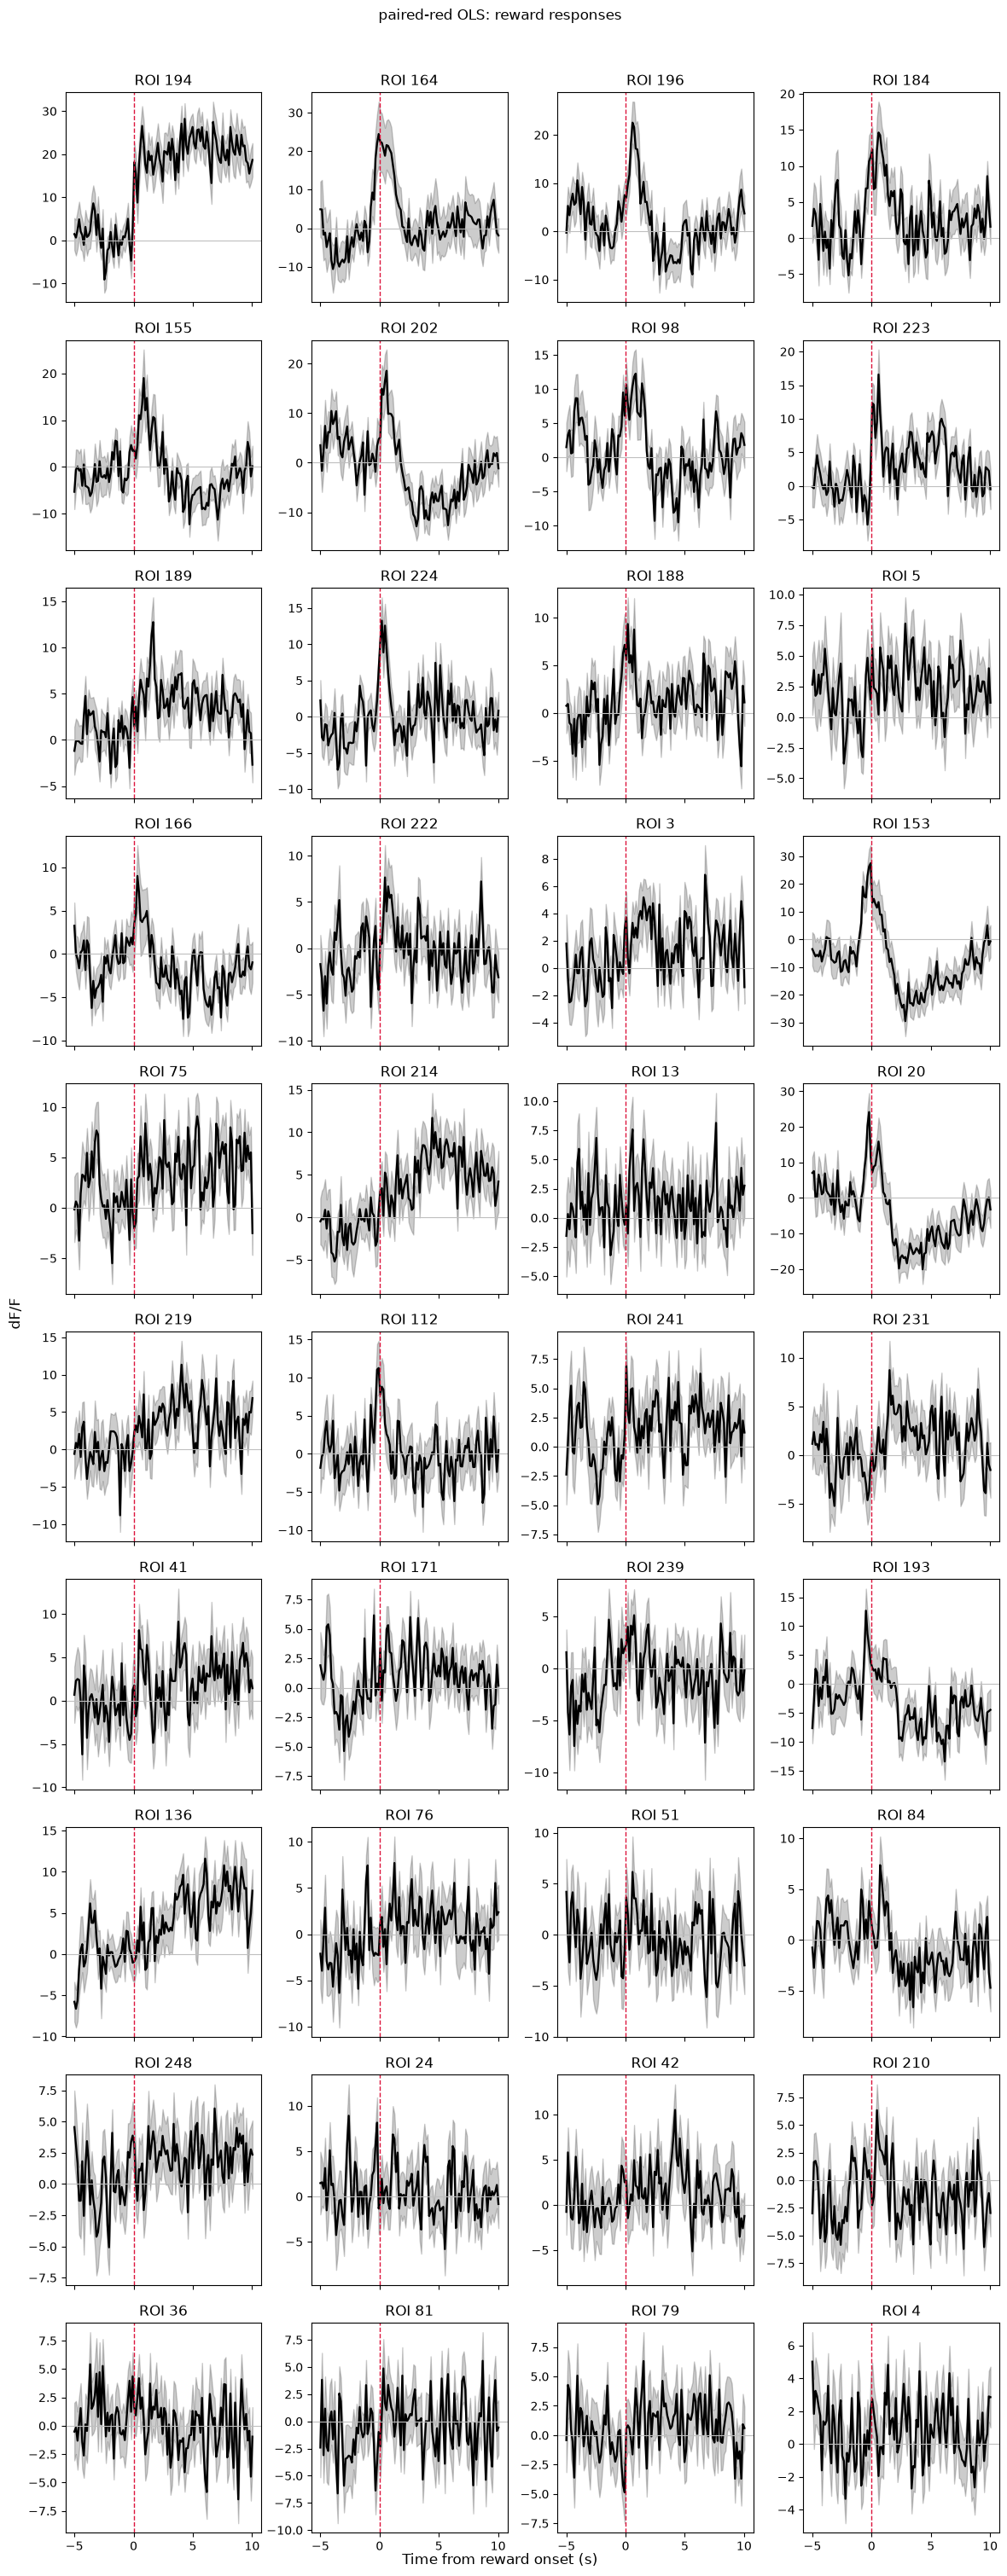

In [10]:
roi_mean = np.nanmean(peri_reward, axis=0)
counts = np.sum(np.isfinite(peri_reward), axis=0)
roi_sem = np.nanstd(peri_reward, axis=0, ddof=1) / np.sqrt(np.maximum(counts, 1))
response_mask = (relative_time >= 0) & (relative_time <= 2)
response = np.nanmean(roi_mean[:, response_mask], axis=1)
roi_order = valid_roi_indices[np.argsort(response[valid_roi_indices])[::-1]]
N_ROIS_TO_PLOT = min(40, len(roi_order))
ROIS_TO_PLOT = roi_order[:N_ROIS_TO_PLOT]
ncols = 4
nrows = int(np.ceil(len(ROIS_TO_PLOT) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3 * nrows), sharex=True, squeeze=False)
for ax, roi in zip(axes.flat, ROIS_TO_PLOT):
    ax.plot(relative_time, roi_mean[roi], color='black', lw=1.7)
    ax.fill_between(relative_time, roi_mean[roi] - roi_sem[roi], roi_mean[roi] + roi_sem[roi], color='black', alpha=.2)
    ax.axvline(0, color='crimson', ls='--', lw=1)
    ax.axhline(0, color='0.75', lw=.8)
    ax.set_title(f'ROI {roi}')
for ax in axes.flat[len(ROIS_TO_PLOT):]:
    ax.set_visible(False)
fig.supxlabel('Time from reward onset (s)')
fig.supylabel('dF/F')
fig.suptitle(f'{method_info["display_name"]}: reward responses', y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'peri_reward_per_cell_mean_sem.png', dpi=200, bbox_inches='tight')
plt.show()

## Twenty most responsive cells by reward magnitude

ROIs are ranked by the absolute value of their trial-averaged 0–2 s response across all rewarded trials. For each selected ROI, separate mean ± SEM traces are then shown for each delivered reward magnitude. Ranking by absolute response includes both activated and inhibited cells.

Most responsive ROI IDs: [125, 126, 174, 194, 109, 45, 164, 131, 32, 154, 182, 12, 196, 106, 140, 89, 100, 191, 60, 184, 155, 107, 72, 202, 132, 98, 221, 138, 223, 1, 183, 157, 85, 189, 70, 25, 168, 53, 199, 133]


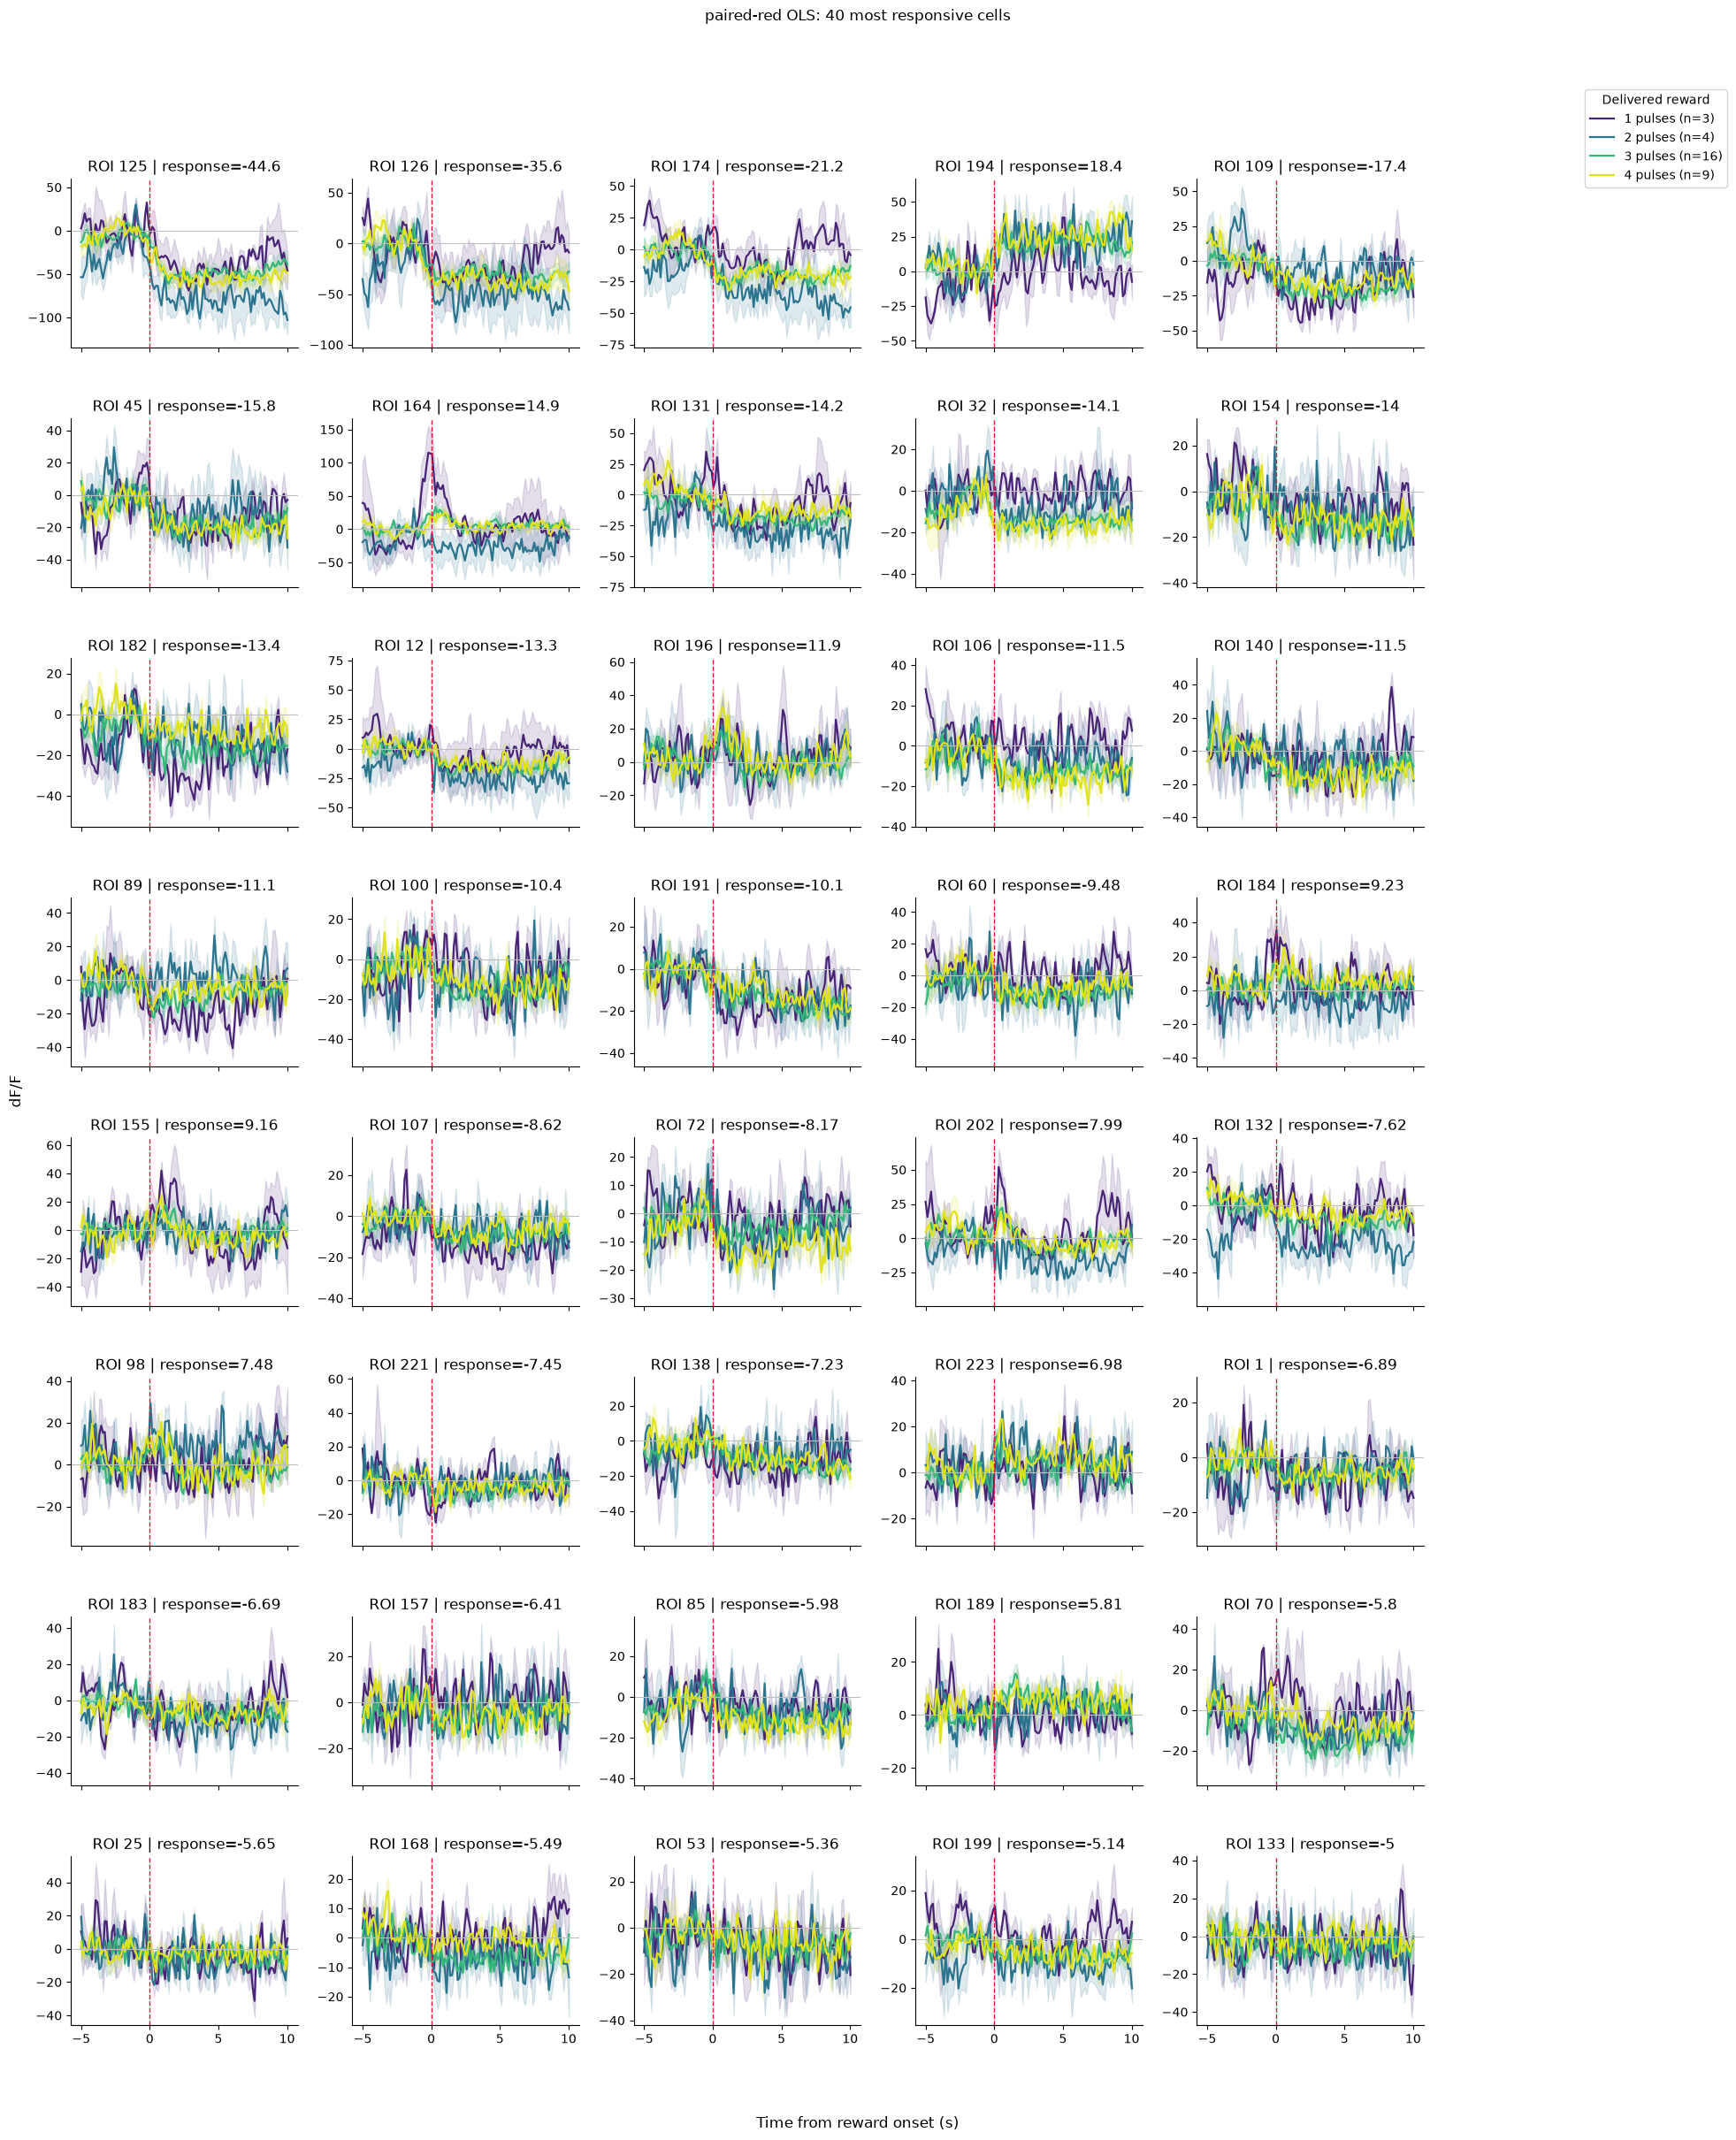

In [11]:
N_MOST_RESPONSIVE = min(40, len(valid_roi_indices))
ranking_score = np.abs(response[valid_roi_indices])
MOST_RESPONSIVE_ROIS = valid_roi_indices[
    np.argsort(np.nan_to_num(ranking_score, nan=-np.inf))[::-1]
][:N_MOST_RESPONSIVE]
magnitudes = np.unique(reward_magnitudes[np.isfinite(reward_magnitudes)])
colors = plt.cm.viridis(np.linspace(0.1, 0.95, len(magnitudes)))
print('Most responsive ROI IDs:', MOST_RESPONSIVE_ROIS.tolist())

ncols = 5
nrows = int(np.ceil(len(MOST_RESPONSIVE_ROIS) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(20, 3 * nrows), sharex=True, squeeze=False)
for ax, roi in zip(axes.flat, MOST_RESPONSIVE_ROIS):
    for color, magnitude in zip(colors, magnitudes):
        use = reward_magnitudes == magnitude
        traces = peri_reward[use, roi, :]
        mean = np.nanmean(traces, axis=0)
        counts = np.sum(np.isfinite(traces), axis=0)
        sem = np.nanstd(traces, axis=0, ddof=1) / np.sqrt(np.maximum(counts, 1))
        ax.plot(relative_time, mean, color=color, lw=1.6,
                label=f'{magnitude:g} pulses (n={use.sum()})')
        ax.fill_between(relative_time, mean - sem, mean + sem,
                        color=color, alpha=0.15)
    ax.axvline(0, color='crimson', ls='--', lw=1)
    ax.axhline(0, color='0.75', lw=0.8)
    ax.set_title(f'ROI {roi} | response={response[roi]:.3g}')
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.flat[len(MOST_RESPONSIVE_ROIS):]:
    ax.set_visible(False)
if len(MOST_RESPONSIVE_ROIS):
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, title='Delivered reward', loc='upper right',
               bbox_to_anchor=(0.995, 0.975), frameon=True)
fig.supxlabel('Time from reward onset (s)')
fig.supylabel('dF/F')
fig.suptitle(
    f'{method_info["display_name"]}: {len(MOST_RESPONSIVE_ROIS)} most responsive cells',
    y=1.01)
fig.subplots_adjust(left=0.055, right=0.82, bottom=0.06, top=0.93,
                    hspace=0.42, wspace=0.24)
fig.savefig(OUTPUT_DIR / 'peri_reward_40_most_responsive_cells.png',
            dpi=200, bbox_inches='tight')
plt.show()

## Trial-averaged ROI heatmap

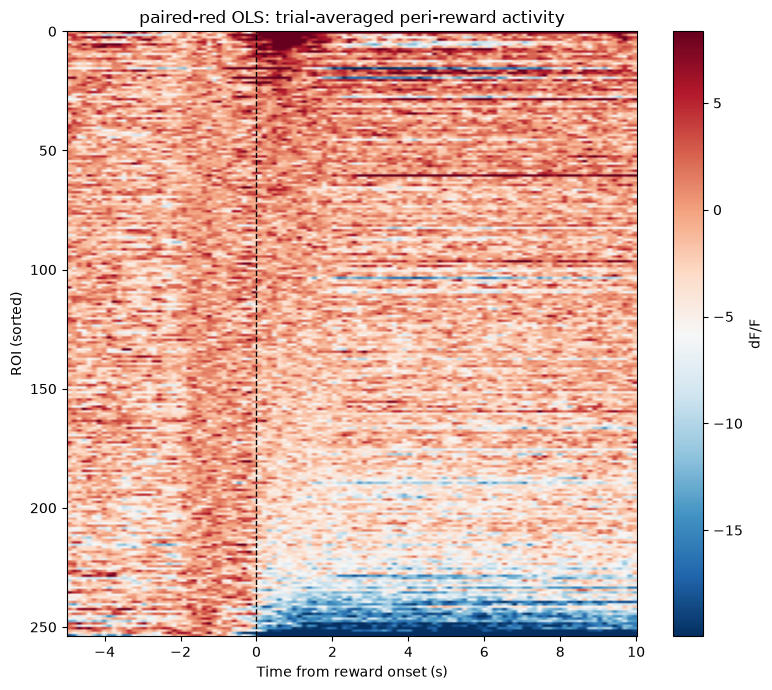

In [12]:
sorted_roi_mean = roi_mean[roi_order]
vmin, vmax = np.nanpercentile(sorted_roi_mean, TRACE_DISPLAY_PERCENTILES)
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(
    sorted_roi_mean, aspect='auto', origin='upper',
    extent=[relative_time[0], relative_time[-1], len(roi_order), 0],
    cmap='RdBu_r', vmin=vmin, vmax=vmax)
ax.axvline(0, color='black', ls='--', lw=1)
ax.set(xlabel='Time from reward onset (s)', ylabel='ROI (sorted)',
       title=f'{method_info["display_name"]}: trial-averaged peri-reward activity')
fig.colorbar(image, ax=ax, label='dF/F')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'peri_reward_roi_heatmap.png', dpi=200)
plt.show()